# ⭐ Notebook 05 — Feature Fusion & Analysis

**Phase 7 of the project — The Core Contribution**

This is the heart of your project title: *Hybrid Texture Fusion Framework*

We combine GLCM (18 features) + LBP (54 features) = **72 fused features**

We also visualize:
- Feature correlations
- t-SNE plot showing how well features separate the classes
- PCA plot

**Run each cell with Shift+Enter**

In [1]:
import sys
sys.path.insert(0, r'D:\Projects\ML')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from src.config import (FEATURES_GLCM_CSV, FEATURES_LBP_CSV,
                        FEATURES_FUSED_CSV, FIGURES_DIR, RANDOM_SEED)
from src.utils import set_plot_style, save_figure

set_plot_style()
print('Imports done!')

Imports done!


## 1. Load GLCM and LBP Features

In [2]:
glcm_df = pd.read_csv(FEATURES_GLCM_CSV)
lbp_df  = pd.read_csv(FEATURES_LBP_CSV)

glcm_cols = [c for c in glcm_df.columns if c.startswith('glcm_')]
lbp_cols  = [c for c in lbp_df.columns  if c.startswith('lbp_')]

print(f'GLCM features loaded: {glcm_df.shape}  ({len(glcm_cols)} feature columns)')
print(f'LBP  features loaded: {lbp_df.shape}   ({len(lbp_cols)} feature columns)')

GLCM features loaded: (7909, 25)  (18 feature columns)
LBP  features loaded: (7909, 61)   (54 feature columns)


## 2. Fuse Features (Strategy C — Main Contribution)

In [3]:
# Merge GLCM + LBP on image_path
fused_df = glcm_df.merge(
    lbp_df[['image_path'] + lbp_cols],
    on='image_path'
)

fused_df.to_csv(FEATURES_FUSED_CSV, index=False)

print('FUSED Feature Matrix:')
print(f'  Shape         : {fused_df.shape}')
print(f'  GLCM features : {len(glcm_cols)}')
print(f'  LBP  features : {len(lbp_cols)}')
print(f'  Total features: {len(glcm_cols) + len(lbp_cols)}')
print(f'  Saved to      : {FEATURES_FUSED_CSV}')
fused_df[glcm_cols + lbp_cols].head(3)

FUSED Feature Matrix:
  Shape         : (7909, 79)
  GLCM features : 18
  LBP  features : 54
  Total features: 72
  Saved to      : D:\Projects\ML\features_fused.csv


,glcm_d1_contrast,glcm_d1_dissimilarity,glcm_d1_homogeneity,glcm_d1_energy,glcm_d1_ASM,glcm_d1_correlation,glcm_d2_contrast,glcm_d2_dissimilarity,glcm_d2_homogeneity,glcm_d2_energy,...,lbp_P24R3_bin16,lbp_P24R3_bin17,lbp_P24R3_bin18,lbp_P24R3_bin19,lbp_P24R3_bin20,lbp_P24R3_bin21,lbp_P24R3_bin22,lbp_P24R3_bin23,lbp_P24R3_bin24,lbp_P24R3_bin25
0,10.967864,2.085404,0.470725,0.119589,0.014348,0.854326,17.260132,2.655135,0.416898,0.111431,...,0.011181,0.011699,0.010144,0.012775,0.015884,0.021724,0.027344,0.028520,0.069436,0.480329
1,10.937138,2.126562,0.448115,0.118089,0.014011,0.836518,17.131437,2.694956,0.391359,0.109372,...,0.009407,0.011141,0.009766,0.011041,0.015306,0.022162,0.028619,0.031808,0.064493,0.492327
2,15.191144,2.572755,0.404549,0.083935,0.007082,0.805126,24.230497,3.302833,0.347193,0.075425,...,0.011221,0.010882,0.010782,0.013791,0.017319,0.024215,0.029416,0.025690,0.063915,0.459323


## 3. Feature Statistics — Benign vs Malignant

In [4]:
all_feat_cols = glcm_cols + lbp_cols

stats = fused_df.groupby('class_name')[all_feat_cols].mean()
print('Mean feature values per class (first 10 features):')
print(stats[all_feat_cols[:10]].T.to_string())

Mean feature values per class (first 10 features):
class_name                benign  malignant
glcm_d1_contrast       21.790418  18.676316
glcm_d1_dissimilarity   2.912460   2.776053
glcm_d1_homogeneity     0.390853   0.396891
glcm_d1_energy          0.091801   0.091133
glcm_d1_ASM             0.010632   0.010232
glcm_d1_correlation     0.787706   0.810230
glcm_d2_contrast       32.007168  29.049325
glcm_d2_dissimilarity   3.634601   3.526258
glcm_d2_homogeneity     0.337729   0.342200
glcm_d2_energy          0.084402   0.083563


## 4. PCA Visualization — Feature Separability

📊  Saved figure → D:\Projects\ML\outputs\figures\05_pca_visualization.png


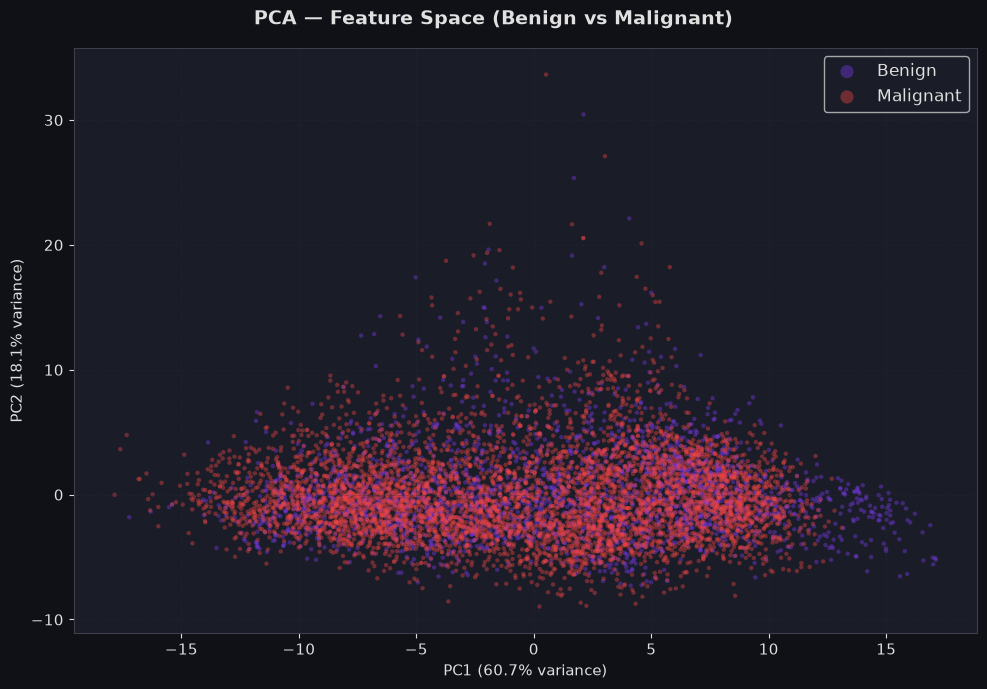

Total variance explained by 2 PCs: 78.9%


In [5]:
X = fused_df[all_feat_cols].values
y = fused_df['label'].values
labels = fused_df['class_name'].values

# Scale first
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA to 2D
pca = PCA(n_components=2, random_state=RANDOM_SEED)
X_pca = pca.fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(10, 7))
fig.suptitle('PCA — Feature Space (Benign vs Malignant)', fontsize=14)
PALETTE = {'benign': '#7c3aed', 'malignant': '#ef4444'}

for cls in ['benign', 'malignant']:
    mask = labels == cls
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
               c=PALETTE[cls], label=cls.capitalize(),
               alpha=0.4, s=10, edgecolors='none')

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
ax.legend(markerscale=3, fontsize=12)
ax.grid(True, alpha=0.3)

plt.tight_layout()
save_figure(fig, FIGURES_DIR / '05_pca_visualization.png')
plt.show()
print(f'Total variance explained by 2 PCs: {sum(pca.explained_variance_ratio_)*100:.1f}%')

## 5. t-SNE Visualization (Publication Quality)

Running t-SNE (takes ~1-2 minutes)...
📊  Saved figure → D:\Projects\ML\outputs\figures\05_tsne_visualization.png


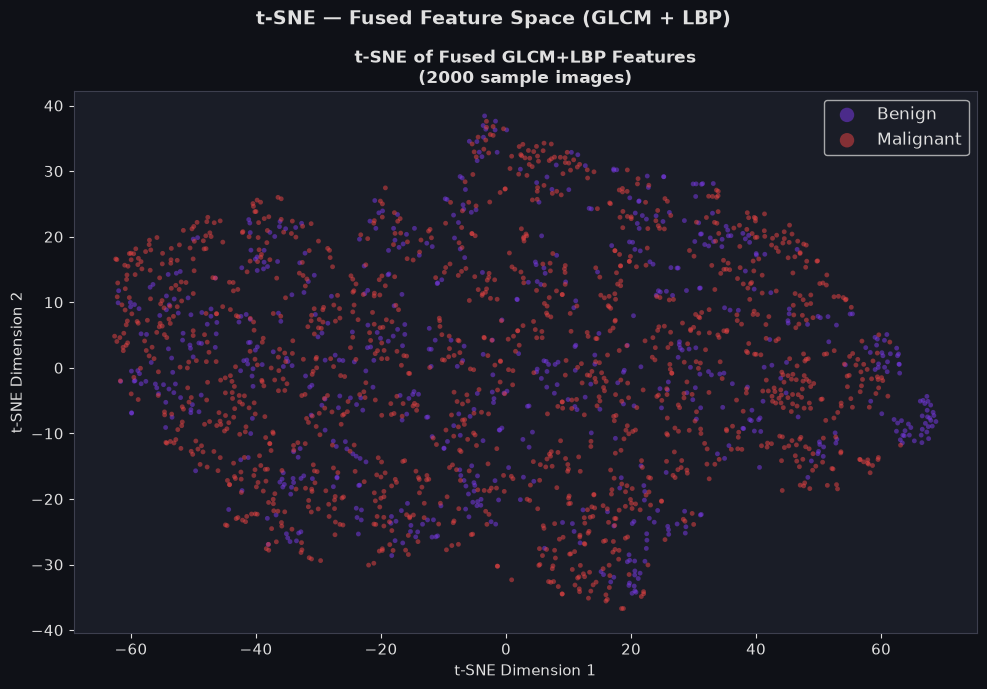

If clusters are separated -> features effectively discriminate the classes!


In [7]:
# t-SNE on a sample (2000 images) for speed
sample_idx = np.random.RandomState(RANDOM_SEED).choice(len(X_scaled), 2000, replace=False)
X_sample   = X_scaled[sample_idx]
y_sample   = labels[sample_idx]

print('Running t-SNE (takes ~1-2 minutes)...')
tsne = TSNE(n_components=2, random_state=RANDOM_SEED,
            perplexity=30, max_iter=1000, verbose=0)

X_tsne = tsne.fit_transform(X_sample)

fig, ax = plt.subplots(figsize=(10, 7))
fig.suptitle('t-SNE — Fused Feature Space (GLCM + LBP)', fontsize=14)

for cls in ['benign', 'malignant']:
    mask = y_sample == cls
    ax.scatter(X_tsne[mask, 0], X_tsne[mask, 1],
               c=PALETTE[cls], label=cls.capitalize(),
               alpha=0.5, s=12, edgecolors='none')

ax.set_xlabel('t-SNE Dimension 1')
ax.set_ylabel('t-SNE Dimension 2')
ax.legend(markerscale=3, fontsize=12)
ax.set_title('t-SNE of Fused GLCM+LBP Features\n(2000 sample images)', fontsize=12)

plt.tight_layout()
save_figure(fig, FIGURES_DIR / '05_tsne_visualization.png')
plt.show()
print('If clusters are separated -> features effectively discriminate the classes!')

## 6. Feature Correlation Heatmap (GLCM features)

📊  Saved figure → D:\Projects\ML\outputs\figures\05_glcm_correlation.png


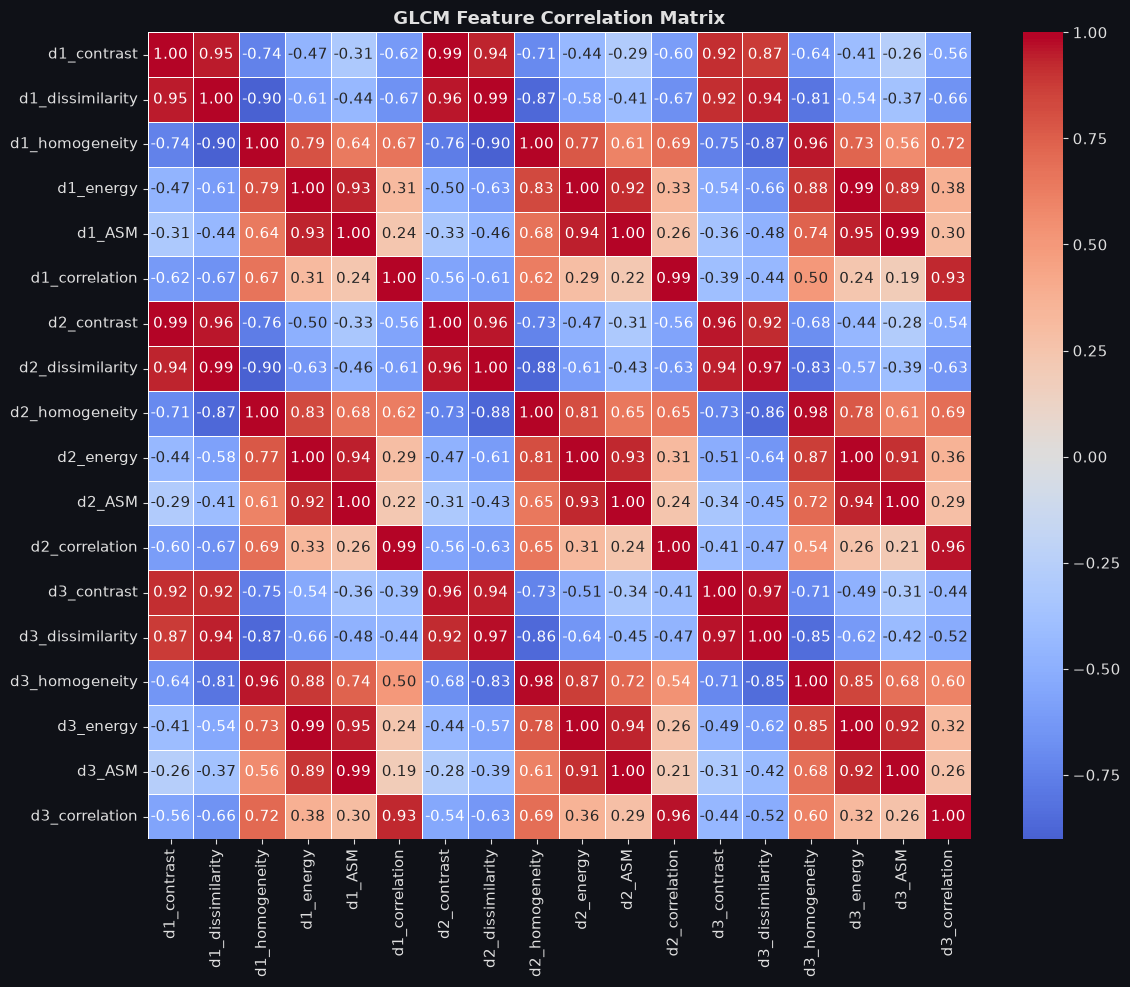

In [8]:
fig, ax = plt.subplots(figsize=(12, 10))
corr = fused_df[glcm_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, ax=ax,
            xticklabels=[c.replace('glcm_','') for c in glcm_cols],
            yticklabels=[c.replace('glcm_','') for c in glcm_cols])
ax.set_title('GLCM Feature Correlation Matrix', fontsize=13)
plt.tight_layout()
save_figure(fig, FIGURES_DIR / '05_glcm_correlation.png')
plt.show()

## 7. Summary

In [9]:
print('='*55)
print('  PHASE 7 COMPLETE - Feature Fusion & Analysis')
print('='*55)
print(f'  GLCM features  : {len(glcm_cols)}')
print(f'  LBP  features  : {len(lbp_cols)}')
print(f'  FUSED features : {len(glcm_cols)+len(lbp_cols)}')
print(f'  features_fused.csv saved!')
print(f'  PCA + t-SNE plots saved!')
print()
print('  Next: Notebook 06 - All ML Classifiers')
print('='*55)

  PHASE 7 COMPLETE - Feature Fusion & Analysis
  GLCM features  : 18
  LBP  features  : 54
  FUSED features : 72
  features_fused.csv saved!
  PCA + t-SNE plots saved!

  Next: Notebook 06 - All ML Classifiers
